# FP2 Long-Run Reconstruction — Monza 2026

**An independent reconstruction of Ruth Buscombe's Friday long-run table from official timing**

*Standalone notebook · deterministic · runs offline from stored FastF1 timing*

Ruth Buscombe's Monza 2026 race briefing contains a chart titled *"Friday long runs, every clean stint of five
laps or more"*: for 18 drivers, the average of clean laps in their best FP2 long run, expressed as a gap to the
fastest long run, with the compound and number of laps. This notebook rebuilds that table **from the raw FP2 lap
timing**, following her stated method, and compares the result with her published values.

It is self-contained: it does **not** import the project's simulator or its pace-estimation functions. Every
step is implemented below, and every choice that her description does not fix is labelled as such.

| Label | Meaning |
|---|---|
| **STATED** | part of the method as Ruth describes it |
| **CHOICE** | an implementation decision her description does not determine |
| **OBSERVED** | official FP2 timing (via FastF1) |
| **PUBLISHED** | a value printed in Ruth's chart |
| **RECONSTRUCTED** | a value computed here from OBSERVED timing |

## 1. Ruth's stated method

The method is printed on the chart itself (stored in `data/sources/article_images/`; the values were transcribed to
`data/published/ruth_fp2_long_runs.csv`):

> *"Friday long runs, every clean stint of five laps or more."* (header)
>
> *"Average of clean laps in each driver's best long run in FP2, as a gap to the fastest (Lawson, hard, 12 laps).
> Compound and stint length on the right. Fuel loads are unknown, so read the groups, not the hundredths."*
> (subtitle)
>
> *"Clean laps are within two per cent of the stint median; out laps and in laps removed."* (footnote)
>
> *"no FP2 long run: Piastri, Bortoleto, Bearman, Alonso"* (chart note)

Read as a procedure:
1. remove **in-laps and out-laps**;
2. keep laps within **2 % of the stint median** ("clean laps");
3. a stint qualifies if it has **at least five clean laps**;
4. for each driver, take the **best** qualifying stint, read as the one with the **fastest average** clean lap;
5. express each selected average as a **gap to the fastest** selected long run.

These long-run gaps are **not** her race-pace inputs. Her *Friday-weighted* race pace is a separate, blended
quantity, half this long-run gap and half the qualifying gap (§8). This notebook reconstructs only the long-run
table.

In [1]:
# --- Environment ------------------------------------------------------------------------------------------------
from __future__ import annotations

import platform
import sys
from dataclasses import dataclass, replace
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd()
assert (ROOT / "data" / "timing").is_dir(), "Run this notebook from the project root."
OUT = ROOT / "outputs" / "fp2_long_run_reconstruction"      # a new folder: no existing project file is written
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | outputs -> {OUT.relative_to(ROOT)}")

Python 3.13.2 | numpy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2 | outputs -> outputs/fp2_long_run_reconstruction


## 2. Data: FP2 lap timing (OBSERVED)

The FP2 laps were downloaded with **FastF1 3.8.3** (official F1 live timing) by `scripts/fetch_timing_data.py` and
stored as `data/timing/fp2_laps.csv`, which is reused here. One row per lap, with the FastF1 fields:

| Field | Meaning (FastF1) | Used for |
|---|---|---|
| `Driver`, `Stint`, `LapNumber` | driver, tyre stint (it changes at every pit stop), lap of the session | grouping |
| `Compound`, `TyreLife`, `FreshTyre` | tyre compound, its age in laps, whether the set was new | reporting |
| `LapTime_s` | lap time in seconds (missing when not timed) | averages |
| `PitIn`, `PitOut` | the lap ended in the pit lane (`PitInTime` set) / started from it (`PitOutTime` set) | in/out-lap removal |
| `TrackStatus` | track-status codes seen during the lap (`1` = green; `12` = green then yellow) | green-flag filter (CHOICE) |
| `IsAccurate`, `Deleted` | FastF1's timing-accuracy flag; lap deleted by the stewards | reported only |

If the stored file is missing, the loader below fetches the same session with FastF1 into memory (internet
needed); it never writes into `data/`.

In [2]:
FP2_CSV = ROOT / "data" / "timing" / "fp2_laps.csv"
COLUMNS = ["Driver", "Team", "LapNumber", "Stint", "Compound", "TyreLife", "FreshTyre", "TrackStatus", "Deleted",
           "IsAccurate", "LapTime_s", "PitIn", "PitOut"]


def load_fp2_laps() -> tuple[pd.DataFrame, str]:
    """Stored FastF1 timing if present; otherwise fetch FP2 with FastF1 (kept in memory only)."""
    if FP2_CSV.exists():
        return pd.read_csv(FP2_CSV), f"stored FastF1 export: {FP2_CSV.relative_to(ROOT)}"
    import fastf1                                              # only needed without the stored file
    cache = OUT / "fastf1_cache"
    cache.mkdir(exist_ok=True)
    fastf1.Cache.enable_cache(str(cache))
    session = fastf1.get_session(2026, "Italian Grand Prix", "FP2")
    session.load(laps=True, telemetry=False, weather=False, messages=False)
    laps = session.laps.copy()
    laps["LapTime_s"] = laps["LapTime"].dt.total_seconds()
    laps["PitIn"], laps["PitOut"] = laps["PitInTime"].notna(), laps["PitOutTime"].notna()
    laps["TrackStatus"] = pd.to_numeric(laps["TrackStatus"], errors="coerce")
    return laps[COLUMNS].reset_index(drop=True), f"FastF1 {fastf1.__version__}, downloaded now"


laps, SOURCE = load_fp2_laps()
laps = laps.astype({"LapNumber": int, "Stint": int})
print("Source:", SOURCE)
print(f"{len(laps)} laps, {laps.Driver.nunique()} drivers, {laps.groupby(['Driver', 'Stint']).ngroups} driver-stints")
checks = pd.Series({
    "laps without a lap time": int(laps.LapTime_s.isna().sum()),
    "in-laps (PitIn)": int(laps.PitIn.sum()),
    "out-laps (PitOut)": int(laps.PitOut.sum()),
    "laps flagged both in and out": int((laps.PitIn & laps.PitOut).sum()),
    "laps not fully green (TrackStatus != 1)": int((laps.TrackStatus != 1).sum()),
    "laps marked not accurate by FastF1 (IsAccurate = False)": int((~laps.IsAccurate).sum()),
    "laps with a 'Deleted' value recorded": int(laps.Deleted.notna().sum()),
}, name="count")
display(checks.to_frame())
display(laps[laps.TrackStatus != 1][["Driver", "Stint", "LapNumber", "TrackStatus", "LapTime_s", "PitIn", "PitOut"]])

Source: stored FastF1 export: data/timing/fp2_laps.csv
618 laps, 22 drivers, 97 driver-stints


,count
laps without a lap time,100
in-laps (PitIn),97
out-laps (PitOut),97
laps flagged both in and out,2
laps not fully green (TrackStatus != 1),6
laps marked not accurate by FastF1 (IsAccurate = False),206
laps with a 'Deleted' value recorded,0


,Driver,Stint,LapNumber,TrackStatus,LapTime_s,PitIn,PitOut
131,PER,3,28,12,NaN,True,False
266,TSU,3,29,12,128.239,True,False
297,ALB,4,31,12,127.060,True,False
362,LAW,3,37,12,NaN,True,False
534,RUS,6,31,12,148.900,True,False
588,PIA,4,26,12,142.103,True,False


**What the data checks show.**
- About a sixth of the laps have no lap time; they cannot enter an average.
- Every lap with a non-green status (`12`) is also an in-lap, so a green-flag filter is **redundant on this
  session**. It is kept as an explicit, labelled choice and its effect is tested in §6.
- FastF1's `Deleted` field is empty for every lap, so track-limit deletions cannot be applied. That is not part
  of Ruth's method anyway.
- `IsAccurate` is reported but **not** used to filter, because Ruth's method does not mention it; §6 shows what
  would change if it were.

## 3. The implementation, step by step

| Step | Rule | Status |
|---|---|---|
| 1 | Drop laps without a recorded lap time | CHOICE (an untimed lap cannot be averaged) |
| 2 | Drop **out-laps** (`PitOut`) and **in-laps** (`PitIn`) | STATED |
| 3 | Drop laps whose track status is not fully green (`TrackStatus != 1`) | CHOICE (green-flag filter; not mentioned by Ruth) |
| 4 | Compute each stint's **median** lap time over the laps that survive steps 1–3 | CHOICE (order: median *after* removing in/out and non-green laps) |
| 5 | Keep laps with $\lvert t - \tilde t\rvert \le 0.02\,\tilde t$ ("within two per cent of the stint median") | STATED; the *symmetric* reading is a CHOICE (a one-sided reading, $t \le 1.02\,\tilde t$, is tested in §6) |
| 6 | One pass only: the median is not recomputed after step 5 | CHOICE |
| 7 | A stint is **eligible** if it has at least **five** clean laps | STATED |
| 8 | Each driver's long run = the eligible stint with the **fastest mean** clean lap | STATED ("best"), read as fastest average |
| 9 | Gap = selected mean − fastest selected mean, over all drivers with a long run | STATED |
| 10 | No driver-specific exceptions | CHOICE (discrepancies are reported, not removed) |

Each lap gets **one** reason for rejection: the first rule in this order that it fails.

In [3]:
@dataclass(frozen=True)
class Method:
    name: str
    tolerance: float = 0.02            # STATED: two per cent
    symmetric: bool = True             # CHOICE: |t - median| <= tol*median (False: t <= (1+tol)*median)
    green_only: bool = True            # CHOICE: drop laps with TrackStatus != 1
    median_after_exclusions: bool = True   # CHOICE: median over laps left after steps 1-3 (False: over all timed laps)
    require_accurate: bool = False     # CHOICE: not used (FastF1 IsAccurate)
    iterate_median: bool = False       # CHOICE: single pass (True: recompute the median until the clean set is stable)
    min_clean: int = 5                 # STATED: five clean laps or more


BASELINE = Method("baseline")


def audit_laps(laps: pd.DataFrame, m: Method) -> pd.DataFrame:
    """One row per lap: clean or rejected, with the FIRST failed rule as the reason."""
    a = laps.copy()
    a["reason"] = ""
    a.loc[a.LapTime_s.isna(), "reason"] = "no lap time"
    a.loc[(a.reason == "") & a.PitOut, "reason"] = "out-lap"
    a.loc[(a.reason == "") & a.PitIn, "reason"] = "in-lap"
    if m.green_only:
        a.loc[(a.reason == "") & (a.TrackStatus != 1), "reason"] = "not green (TrackStatus != 1)"
    if m.require_accurate:
        a.loc[(a.reason == "") & ~a.IsAccurate, "reason"] = "not accurate (FastF1)"
    base = (a.reason == "") if m.median_after_exclusions else a.LapTime_s.notna()
    a["stint_median_s"] = np.nan
    a["deviation_pct"] = np.nan
    for (_, _), idx in a.groupby(["Driver", "Stint"]).groups.items():
        pool = a.loc[idx][base.loc[idx]]
        if pool.empty:
            continue
        med = pool.LapTime_s.median()
        candidates = a.loc[idx][a.loc[idx].reason == ""]
        for _ in range(20 if m.iterate_median else 1):
            dev = (candidates.LapTime_s - med) / med
            ok = dev.abs() <= m.tolerance + 1e-12 if m.symmetric else dev <= m.tolerance + 1e-12
            new_med = candidates.LapTime_s[ok].median() if ok.any() else med
            if not m.iterate_median or np.isclose(new_med, med):
                break
            med = new_med
        a.loc[idx, "stint_median_s"] = med
        a.loc[candidates.index, "deviation_pct"] = 100 * (candidates.LapTime_s - med) / med
        a.loc[ok[~ok].index, "reason"] = "outside 2% of stint median"
    a["clean"] = a.reason == ""
    return a


def summarise_stints(a: pd.DataFrame, m: Method) -> pd.DataFrame:
    g = a.groupby(["Driver", "Stint"])
    s = pd.DataFrame({
        "compound": g.Compound.first(), "tyre age at start": g.TyreLife.min(), "new set": g.FreshTyre.first(),
        "laps in stint": g.size(), "first lap": g.LapNumber.min(), "last lap": g.LapNumber.max(),
        "no time": g.reason.apply(lambda r: (r == "no lap time").sum()),
        "in/out": g.reason.apply(lambda r: r.isin(["in-lap", "out-lap"]).sum()),
        "not green": g.reason.apply(lambda r: (r == "not green (TrackStatus != 1)").sum()),
        "outside 2%": g.reason.apply(lambda r: (r == "outside 2% of stint median").sum()),
        "clean laps": g.clean.sum(),
        "median s": g.stint_median_s.first(),
        "mean clean s": a[a.clean].groupby(["Driver", "Stint"]).LapTime_s.mean(),
    })
    s["clean laps"] = s["clean laps"].astype(int)
    s["eligible"] = s["clean laps"] >= m.min_clean
    s["selected"] = False
    eligible = s[s.eligible].reset_index()
    best = eligible.loc[eligible.groupby("Driver")["mean clean s"].idxmin(), ["Driver", "Stint"]]
    s.loc[list(best.itertuples(index=False, name=None)), "selected"] = True
    return s


def long_runs(s: pd.DataFrame) -> pd.DataFrame:
    sel = s[s.selected].reset_index().set_index("Driver")
    out = sel[["Stint", "compound", "clean laps", "mean clean s", "tyre age at start", "new set"]].copy()
    out["gap s"] = out["mean clean s"] - out["mean clean s"].min()
    return out.sort_values("gap s")


audit = audit_laps(laps, BASELINE)
stints = summarise_stints(audit, BASELINE)
LR = long_runs(stints)
print(f"{audit.clean.sum()} clean laps out of {len(audit)}; {int(stints.eligible.sum())} eligible stints; "
      f"{len(LR)} drivers with a long run; fastest: {LR.index[0]} {LR['mean clean s'].iloc[0]:.3f} s")

258 clean laps out of 618; 20 eligible stints; 19 drivers with a long run; fastest: LAW 86.063 s


## 4. Which laps were kept and why the others were rejected

First the totals by reason, then every driver-stint with its counts and its role. A stint is either
**selected** (the driver's long run), **eligible** (five or more clean laps, but slower than the driver's
selected stint), or **too short** (fewer than five clean laps).

In [4]:
reason_counts = audit.assign(reason=audit.reason.replace("", "clean (retained)")).reason.value_counts().rename("laps")
display(reason_counts.to_frame())

stint_view = stints.copy()
stint_view["role"] = np.where(stint_view.selected, "SELECTED", np.where(stint_view.eligible, "eligible, slower", "too short (<5 clean)"))
stint_view = stint_view.drop(columns=["selected", "eligible"])
display(stint_view.round({"median s": 3, "mean clean s": 3}))
audit.to_csv(OUT / "lap_audit.csv", index=False)
stints.to_csv(OUT / "stint_summary.csv")
print(f"Lap-level audit ({len(audit)} rows) saved to {(OUT / 'lap_audit.csv').relative_to(ROOT)}")

,laps
reason,
clean (retained),258
outside 2% of stint median,154
no lap time,100
in-lap,88
out-lap,18


compound  tyre age at start  new set  laps in stint  first lap  last lap  no time  in/out  not green  outside 2%  clean laps  median s  mean clean s                  role
Driver Stint                                                                                                                                                                           
ALB    1       MEDIUM                1.0     True             11          1        11        1       1          0           8           1   103.728       103.728  too short (<5 clean)
       2         SOFT                1.0     True              3         12        14        1       1          0           0           1    83.853        83.853  too short (<5 clean)
       3       MEDIUM               12.0    False             12         15        26        1       1          0           0          10    87.703        87.734              SELECTED
       4         SOFT                4.0    False              5         27        31        1       2          0           2           0   106.682           NaN  too short (<5 clean)
ALO    1         SOFT                1.0     True              7          1         7        1       1          0           2           3    86.319        86.088  too short (<5 clean)
       2         SOFT                1.0     True              6          8        13        1       1          0           4           0   102.114           NaN  too short (<5 clean)
       3         SOFT                7.0    False              5         14        18        1       1          0           2           1   108.541       108.541  too short (<5 clean)
ANT    1         HARD                1.0     True              4          1         4        1       1          0           2           0   108.768           NaN  too short (<5 clean)
       2         SOFT                1.0     True              2          5         6        1       1          0           0           0       NaN           NaN  too short (<5 clean)
       3         SOFT                3.0    False              3          7         9        1       1          0           0           1    82.700        82.700  too short (<5 clean)
       4         HARD                5.0    False             19         10        28        1       1          0           0          17    86.018        86.156              SELECTED
       5         SOFT                6.0    False              4         29        32        1       2          0           0           1   130.172       130.172  too short (<5 clean)
BEA    1       MEDIUM                1.0     True              3          1         3        2       0          0           0           1    85.238        85.238  too short (<5 clean)
       2       MEDIUM                4.0    False              3          4         6        2       0          0           0           1    84.961        84.961  too short (<5 clean)
       3       MEDIUM                7.0    False              4          7        10        1       1          0           2           0   102.082           NaN  too short (<5 clean)
       4         SOFT                1.0     True              3         11        13        1       1          0           0           1    83.690        83.690  too short (<5 clean)
       5         SOFT                4.0    False              4         14        17        1       1          0           2           0   108.266           NaN  too short (<5 clean)
       6       MEDIUM               11.0    False             12         18        29        2       1          0           3           6    87.779        87.506              SELECTED
BOR    1         HARD                1.0     True              5          1         5        1       1          0           1           2    84.666        84.626  too short (<5 clean)
       2         HARD                6.0    False              3          6         8        0       2          0           0           1    84.111  

Lap-level audit (618 rows) saved to outputs/fp2_long_run_reconstruction/lap_audit.csv


The **selected** stints lap by lap: the clean laps that enter each average, and every other lap of the stint with
the reason it was dropped. Deviations are from the stint median.

In [5]:
def lap_listing(driver: str, stint: int) -> dict:
    g = audit[(audit.Driver == driver) & (audit.Stint == stint)].sort_values("LapNumber")
    kept = ", ".join(f"L{r.LapNumber} {r.LapTime_s:.3f}" for r in g[g.clean].itertuples())
    def why(r):
        if r.reason == "outside 2% of stint median":
            return f"L{r.LapNumber} {r.LapTime_s:.3f} ({r.deviation_pct:+.1f}% vs median)"
        return f"L{r.LapNumber} ({r.reason})"
    dropped = "; ".join(why(r) for r in g[~g.clean].itertuples())
    return {"driver": driver, "stint": stint, "compound": g.Compound.iloc[0], "median s": round(g.stint_median_s.iloc[0], 3),
            "clean laps used (lap, time s)": kept, "rejected laps (reason)": dropped}

selected_listing = pd.DataFrame([lap_listing(d, int(r.Stint)) for d, r in LR.iterrows()]).set_index("driver")
display(selected_listing)

,stint,compound,median s,"clean laps used (lap, time s)",rejected laps (reason)
driver,,,,,
LAW,3,HARD,86.128,"L23 86.252, L24 85.964, L25 85.754, L26 85.868, L27 85.883, L28 85.582, L29 86.267, L30 86.571, L31 86.154, L32 86.1...",L22 (out-lap); L35 141.366 (+64.1% vs median); L36 (no lap time); L37 (no lap time)
ANT,4,HARD,86.018,"L11 86.420, L12 86.405, L13 86.291, L14 85.875, L15 85.968, L16 85.702, L17 85.946, L18 85.813, L19 85.739, L20 85.8...",L10 (no lap time); L28 (in-lap)
RUS,5,HARD,86.148,"L17 86.110, L18 86.381, L19 86.304, L20 86.155, L21 85.975, L22 86.140, L23 85.943, L24 87.175, L25 85.742, L26 86.158",L16 (no lap time); L27 (in-lap)
LEC,6,SOFT,86.232,"L17 87.087, L18 86.232, L19 86.168, L22 86.024, L23 86.042, L24 86.323, L25 86.137, L26 85.708",L16 (no lap time); L20 97.380 (+12.9% vs median); L21 88.185 (+2.3% vs median); L27 105.000 (+21.8% vs median); L28 ...
HAM,5,SOFT,86.373,"L16 86.424, L17 86.645, L18 86.373, L19 86.022, L20 86.419, L21 86.002, L22 86.254, L23 85.756, L24 86.261",L15 (no lap time); L25 115.285 (+33.5% vs median); L26 142.738 (+65.3% vs median); L27 (in-lap)
NOR,3,HARD,86.526,"L15 86.361, L16 86.280, L17 86.690, L18 86.311, L20 86.887",L14 (no lap time); L19 89.487 (+3.4% vs median); L21 (in-lap)
VER,4,MEDIUM,86.605,"L18 86.641, L19 86.450, L20 86.605, L21 86.741, L22 86.174",L17 (no lap time); L23 (in-lap)
LIN,4,MEDIUM,86.974,"L16 87.398, L17 87.091, L18 87.295, L19 86.270, L20 87.072, L21 87.121, L22 86.876, L23 86.817, L24 86.799, L25 86.505",L15 (no lap time); L26 (in-lap)
GAS,3,HARD,87.227,"L17 87.339, L18 87.027, L19 87.636, L20 87.619, L21 86.755, L22 86.804, L23 87.116, L24 86.662",L16 (no lap time); L25 113.252 (+29.8% vs median); L26 143.779 (+64.8% vs median); L27 (in-lap)


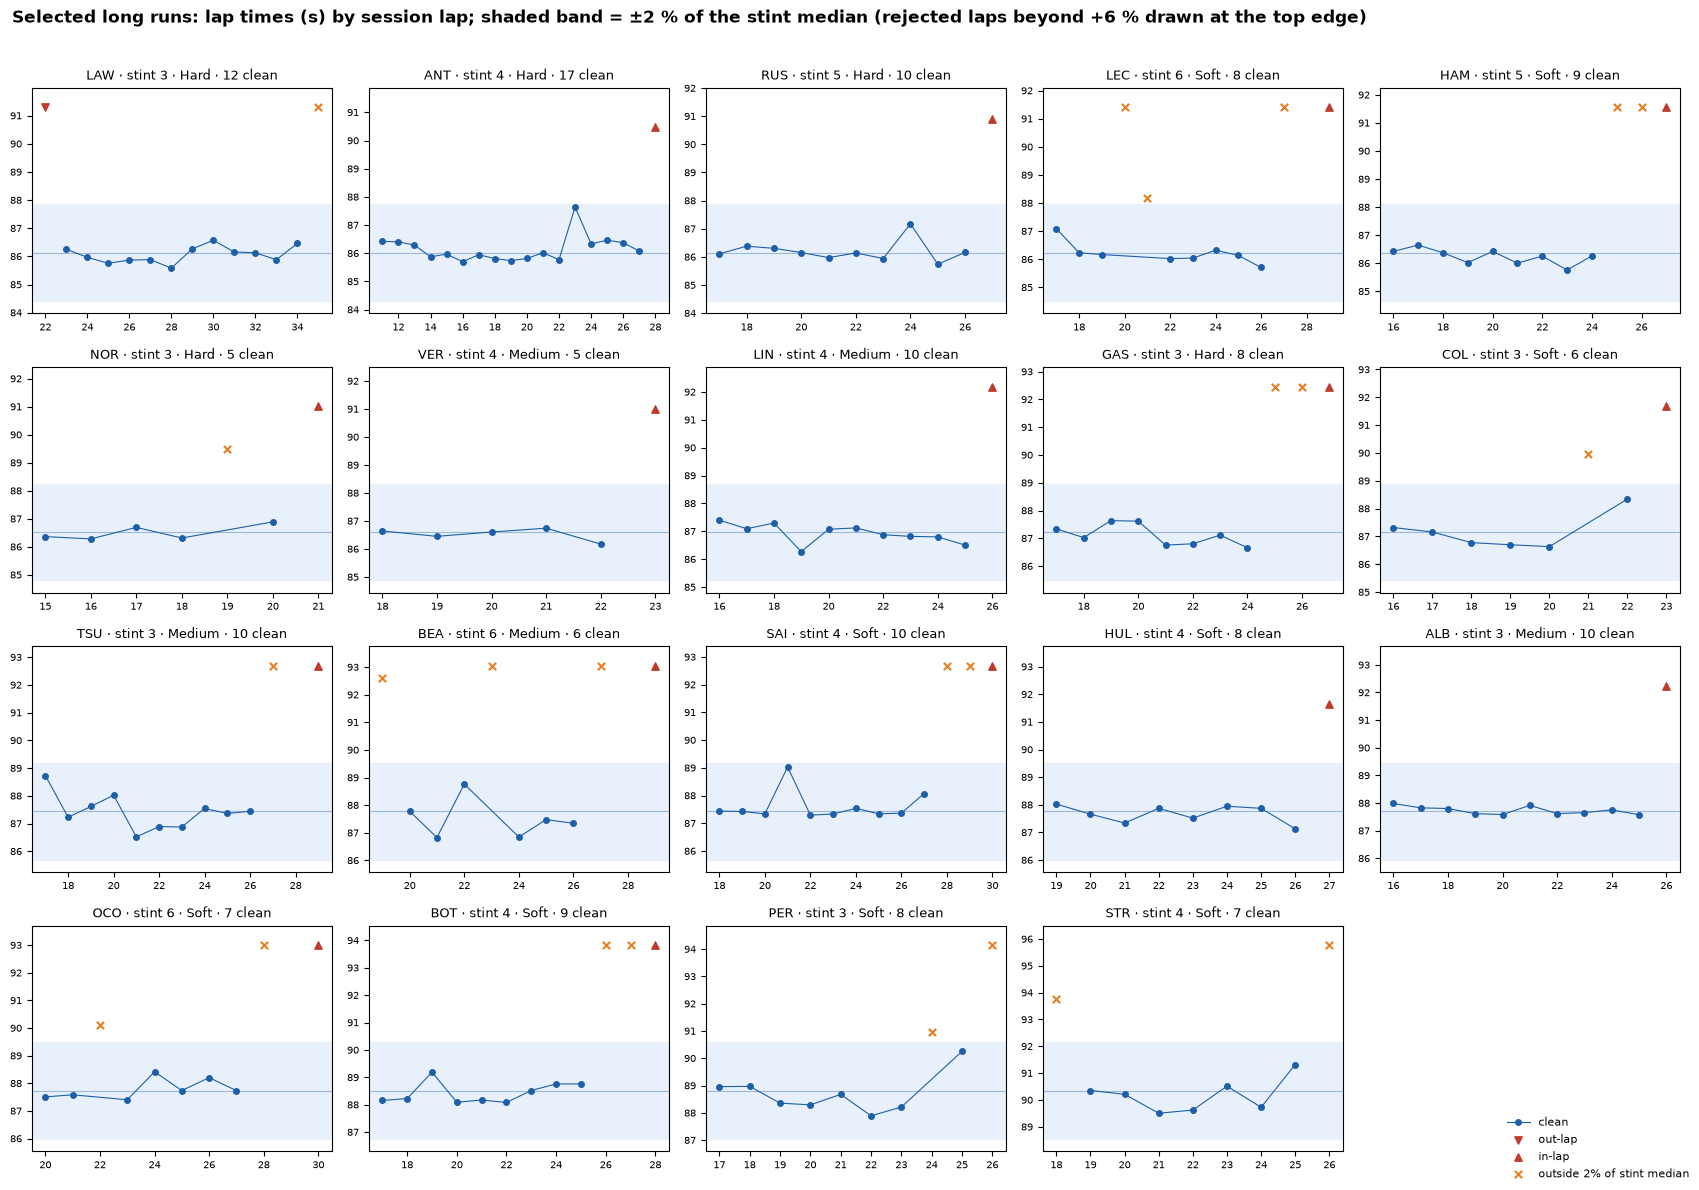

In [6]:
order = list(LR.index)
ncol = 5
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(17, 3.0 * nrow), squeeze=False)
reason_style = {"out-lap": ("v", "#c0392b"), "in-lap": ("^", "#c0392b"), "outside 2% of stint median": ("x", "#e67e22")}
for ax, d in zip(axes.flat, order):
    st = int(LR.loc[d, "Stint"])
    g = audit[(audit.Driver == d) & (audit.Stint == st)].sort_values("LapNumber")
    med = g.stint_median_s.iloc[0]
    ax.axhspan(0.98 * med, 1.02 * med, color="#e8f1fb", zorder=0)
    ax.axhline(med, color="#9db8d9", lw=0.8)
    ax.plot(g[g.clean].LapNumber, g[g.clean].LapTime_s, "o-", color="#1f5fa8", ms=4, lw=0.8, label="clean")
    for reason, (mk, col) in reason_style.items():
        r = g[(g.reason == reason) & g.LapTime_s.notna()]
        ax.scatter(r.LapNumber, r.LapTime_s.clip(upper=1.06 * med), marker=mk, color=col, s=28, label=reason)
    ax.set_ylim(0.975 * med, 1.068 * med)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.set_title(f"{d} · stint {st} · {LR.loc[d, 'compound'].title()} · {int(LR.loc[d, 'clean laps'])} clean", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(order):]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", fontsize=8, frameon=False)
fig.suptitle("Selected long runs: lap times (s) by session lap; shaded band = ±2 % of the stint median "
             "(rejected laps beyond +6 % drawn at the top edge)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97)); fig.savefig(OUT / "selected_long_runs.png", dpi=130); plt.show()

## 5. Comparison with Ruth's published table

Each driver in Ruth's chart is compared on four points:
- the compound;
- the number of laps (the chart labels them "stint length", but the numbers are the counts of *clean* laps);
- the average lap, which she prints to 0.1 s;
- the gap, which she prints to 0.01 s.

A gap "matches" if it agrees within **half a rounding unit (0.005 s)**, the most that two-decimal rounding can
hide.

In [7]:
ruth = pd.read_csv(ROOT / "data" / "published" / "ruth_fp2_long_runs.csv").set_index("driver")
NO_LONG_RUN_PER_RUTH = ["PIA", "BOR", "BEA", "ALO"]          # chart note: "no FP2 long run"

idx = list(LR.index) + [d for d in ruth.index if d not in LR.index]
R, H = ruth.reindex(idx), LR.reindex(idx)
comparison = pd.DataFrame({
    "in Ruth's table": [d in ruth.index for d in idx], "long run found here": [d in LR.index for d in idx],
    "compound (Ruth)": R["compound"], "compound (here)": H["compound"],
    "laps (Ruth)": R["clean_laps"], "clean laps (here)": H["clean laps"],
    "mean lap s (Ruth, 0.1)": R["mean_lap_s"], "mean lap s (here)": H["mean clean s"].round(3),
    "gap s (Ruth)": R["gap_s"], "gap s (here)": H["gap s"].round(4),
}, index=pd.Index(idx, name="driver"))
comparison["|gap error| s"] = (comparison["gap s (here)"] - comparison["gap s (Ruth)"]).abs().round(4)
comparison["compound ok"] = comparison["compound (Ruth)"] == comparison["compound (here)"]
comparison["laps ok"] = comparison["laps (Ruth)"] == comparison["clean laps (here)"]
comparison["mean ok (0.1 s)"] = (comparison["mean lap s (here)"].round(1) == comparison["mean lap s (Ruth, 0.1)"])
comparison["gap ok (≤0.005)"] = comparison["|gap error| s"] <= 0.005 + 1e-12
display(comparison)
comparison.to_csv(OUT / "comparison_with_ruth.csv")

both = comparison[comparison["in Ruth's table"] & comparison["long run found here"]]
print(f"Drivers in Ruth's table: {len(ruth)}; long runs found here: {len(LR)}; in both: {len(both)}")
print(f"  compound agrees: {int(both['compound ok'].sum())}/{len(both)} | clean-lap count agrees: {int(both['laps ok'].sum())}/{len(both)} | "
      f"mean lap agrees to 0.1 s: {int(both['mean ok (0.1 s)'].sum())}/{len(both)} | gap within 0.005 s: {int(both['gap ok (≤0.005)'].sum())}/{len(both)} "
      f"(max |error| {both['|gap error| s'].max():.4f} s)")
only_here = sorted(set(LR.index) - set(ruth.index))
only_ruth = sorted(set(ruth.index) - set(LR.index))
no_lr_here = sorted(set(laps.Driver) - set(LR.index))
print(f"  long run found here but not in Ruth's table: {only_here}")
print(f"  in Ruth's table but no long run found here: {only_ruth}")
print(f"  no long run here: {no_lr_here} | Ruth's 'no FP2 long run' note: {NO_LONG_RUN_PER_RUTH}")

,in Ruth's table,long run found here,compound (Ruth),compound (here),laps (Ruth),clean laps (here),"mean lap s (Ruth, 0.1)",mean lap s (here),gap s (Ruth),gap s (here),|gap error| s,compound ok,laps ok,mean ok (0.1 s),gap ok (≤0.005)
driver,,,,,,,,,,,,,,,
LAW,True,True,HARD,HARD,12.0,12,86.1,86.063,0.00,0.0000,0.0000,True,True,True,True
ANT,True,True,HARD,HARD,17.0,17,86.2,86.156,0.09,0.0923,0.0023,True,True,True,True
RUS,True,True,HARD,HARD,10.0,10,86.2,86.208,0.14,0.1448,0.0048,True,True,True,True
LEC,True,True,SOFT,SOFT,8.0,8,86.2,86.215,0.15,0.1516,0.0016,True,True,True,True
HAM,True,True,SOFT,SOFT,9.0,9,86.2,86.240,0.18,0.1761,0.0039,True,True,True,True
NOR,True,True,HARD,HARD,5.0,5,86.5,86.506,0.44,0.4423,0.0023,True,True,True,True
VER,True,True,MEDIUM,MEDIUM,5.0,5,86.5,86.522,0.46,0.4587,0.0013,True,True,True,True
LIN,True,True,MEDIUM,MEDIUM,10.0,10,86.9,86.924,0.86,0.8609,0.0009,True,True,True,True
GAS,True,True,HARD,HARD,8.0,8,87.1,87.120,1.06,1.0563,0.0037,True,True,True,True


Drivers in Ruth's table: 18; long runs found here: 19; in both: 18
  compound agrees: 18/18 | clean-lap count agrees: 18/18 | mean lap agrees to 0.1 s: 18/18 | gap within 0.005 s: 18/18 (max |error| 0.0049 s)
  long run found here but not in Ruth's table: ['BEA']
  in Ruth's table but no long run found here: []
  no long run here: ['ALO', 'BOR', 'PIA'] | Ruth's 'no FP2 long run' note: ['PIA', 'BOR', 'BEA', 'ALO']


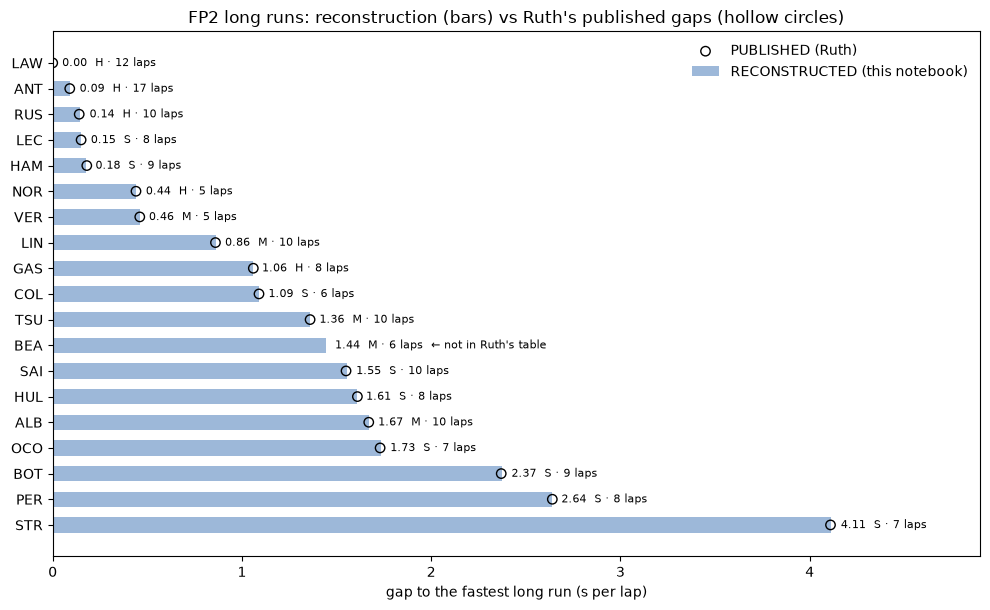

In [8]:
fig, ax = plt.subplots(figsize=(10, 6.2))
y = np.arange(len(LR))[::-1]
ax.barh(y, LR["gap s"], color="#9db8d9", height=0.6, label="RECONSTRUCTED (this notebook)")
r = ruth.reindex(LR.index)["gap_s"]
ax.scatter(r, y, facecolor="none", edgecolor="black", s=46, zorder=3, label="PUBLISHED (Ruth)")
for yi, (d, row) in zip(y, LR.iterrows()):
    tag = "  ← not in Ruth's table" if d not in ruth.index else ""
    ax.text(row["gap s"] + 0.05, yi, f"{row['gap s']:.2f}  {row['compound'][0]} · {int(row['clean laps'])} laps{tag}", va="center", fontsize=8)
ax.set_yticks(y, LR.index)
ax.set(xlabel="gap to the fastest long run (s per lap)", xlim=(0, 4.9),
       title="FP2 long runs: reconstruction (bars) vs Ruth's published gaps (hollow circles)")
ax.legend(loc="upper right", frameon=False)
fig.tight_layout(); fig.savefig(OUT / "gaps_vs_ruth.png", dpi=130); plt.show()

## 6. How much do the implementation choices matter?

Each variant changes **one** choice from §3, and everything else is kept. For each variant the table shows:
- which drivers get a long run;
- how many of Ruth's 18 drivers then match on compound, clean-lap count and gap (within 0.005 s);
- the largest gap error.

This shows which of the labelled choices the agreement depends on.

In [9]:
VARIANTS = [
    BASELINE,
    replace(BASELINE, name="one-sided 2 % (t <= 1.02 median)", symmetric=False),
    replace(BASELINE, name="no green-flag filter", green_only=False),
    replace(BASELINE, name="median over all timed laps (before in/out removal)", median_after_exclusions=False),
    replace(BASELINE, name="iterate the median until stable", iterate_median=True),
    replace(BASELINE, name="also require FastF1 IsAccurate", require_accurate=True),
    replace(BASELINE, name="1 % tolerance", tolerance=0.01),
    replace(BASELINE, name="3 % tolerance", tolerance=0.03),
]
rows, variant_lr = [], {}
for m in VARIANTS:
    s = summarise_stints(audit_laps(laps, m), m)
    lr = long_runs(s)
    variant_lr[m.name] = lr
    j = ruth.join(lr, how="inner", rsuffix="_here")
    err = (j["gap s"] - j["gap_s"]).abs()
    rows.append({"variant": m.name, "drivers with a long run": len(lr),
                 "extra vs Ruth": ", ".join(sorted(set(lr.index) - set(ruth.index))) or "-",
                 "missing vs Ruth": ", ".join(sorted(set(ruth.index) - set(lr.index))) or "-",
                 "compound matches": int((j["compound"] == j["compound_here"]).sum()),
                 "clean-lap matches": int((j["clean_laps"] == j["clean laps"]).sum()),
                 "gap within 0.005 s": int((err <= 0.005 + 1e-12).sum()),
                 "max |gap error| s": round(err.max(), 4),
                 "same selected stints as baseline": bool(lr["Stint"].sort_index().equals(LR["Stint"].sort_index()))})
variants = pd.DataFrame(rows).set_index("variant")
display(variants)
variants.to_csv(OUT / "method_variants.csv")

,drivers with a long run,extra vs Ruth,missing vs Ruth,compound matches,clean-lap matches,gap within 0.005 s,max |gap error| s,same selected stints as baseline
variant,,,,,,,,
baseline,19,BEA,-,18,18,18,0.0049,True
one-sided 2 % (t <= 1.02 median),19,BEA,-,18,18,18,0.0049,True
no green-flag filter,19,BEA,-,18,18,18,0.0049,True
median over all timed laps (before in/out removal),19,BEA,-,18,18,18,0.0049,True
iterate the median until stable,19,BEA,-,18,18,18,0.0049,True
also require FastF1 IsAccurate,19,BEA,-,18,18,18,0.0049,True
1 % tolerance,18,-,-,18,11,11,0.2366,False
3 % tolerance,19,BEA,-,18,15,15,0.2933,True


## 7. Bearman: a discrepancy kept, not removed

Ruth's chart lists Bearman under *"no FP2 long run"*. Applied as stated, the method finds one. The cell below
shows his stints lap by lap, and tests a few rules that *might* explain the omission. They are diagnostics only:
**none is adopted**, because the reconstruction should follow the stated method and report where it disagrees.

In [10]:
bea = audit[audit.Driver == "BEA"].sort_values(["Stint", "LapNumber"])
display(stints.loc["BEA"].drop(columns=["eligible"]).round(3))
display(bea[bea.Stint == int(LR.loc["BEA", "Stint"])][["Stint", "LapNumber", "Compound", "LapTime_s", "deviation_pct", "reason"]]
        .assign(deviation_pct=lambda x: x.deviation_pct.round(2), reason=lambda x: x.reason.replace("", "clean")))


def longest_consecutive(lap_numbers) -> int:
    best = run = 0
    prev = None
    for n in sorted(lap_numbers):
        run = run + 1 if prev is not None and n == prev + 1 else 1
        best, prev = max(best, run), n
    return best

diag = []
for d, row in LR.iterrows():
    clean_laps = audit[(audit.Driver == d) & (audit.Stint == row.Stint) & audit.clean].LapNumber
    diag.append({"driver": d, "in Ruth's table": d in ruth.index, "clean laps": int(row["clean laps"]),
                 "longest run of consecutive clean laps": longest_consecutive(clean_laps),
                 "clean laps on a used set": not bool(row["new set"])})
diag = pd.DataFrame(diag).set_index("driver")
consec = diag["longest run of consecutive clean laps"] >= 5
listed = diag["in Ruth's table"]
print("Candidate rule 'at least five CONSECUTIVE clean laps': would drop", sorted(diag.index[~consec]),
      "- of these, listed in Ruth's table:", sorted(diag.index[~consec & listed]))
display(diag.loc[["BEA", "NOR", "VER", "COL"]])

,compound,tyre age at start,new set,laps in stint,first lap,last lap,no time,in/out,not green,outside 2%,clean laps,median s,mean clean s,selected
Stint,,,,,,,,,,,,,,
1,MEDIUM,1.0,True,3,1,3,2,0,0,0,1,85.238,85.238,False
2,MEDIUM,4.0,False,3,4,6,2,0,0,0,1,84.961,84.961,False
3,MEDIUM,7.0,False,4,7,10,1,1,0,2,0,102.082,NaN,False
4,SOFT,1.0,True,3,11,13,1,1,0,0,1,83.690,83.690,False
5,SOFT,4.0,False,4,14,17,1,1,0,2,0,108.266,NaN,False
6,MEDIUM,11.0,False,12,18,29,2,1,0,3,6,87.779,87.506,True


,Stint,LapNumber,Compound,LapTime_s,deviation_pct,reason
606,6,18,MEDIUM,NaN,NaN,no lap time
607,6,19,MEDIUM,92.615,5.51,outside 2% of stint median
608,6,20,MEDIUM,87.779,0.00,clean
609,6,21,MEDIUM,86.827,-1.08,clean
610,6,22,MEDIUM,88.763,1.12,clean
611,6,23,MEDIUM,104.987,19.60,outside 2% of stint median
612,6,24,MEDIUM,86.847,-1.06,clean
613,6,25,MEDIUM,87.476,-0.35,clean
614,6,26,MEDIUM,87.342,-0.50,clean
615,6,27,MEDIUM,105.738,20.46,outside 2% of stint median


Candidate rule 'at least five CONSECUTIVE clean laps': would drop ['BEA', 'NOR'] - of these, listed in Ruth's table: ['NOR']


,in Ruth's table,clean laps,longest run of consecutive clean laps,clean laps on a used set
driver,,,,
BEA,False,6,3,True
NOR,True,5,4,True
VER,True,5,5,True
COL,True,6,5,True


**Reading the Bearman case.**
* The stated method finds a medium-tyre stint (stint 6) with six clean laps: laps 20–22 and 24–26. Three slower
  laps are rejected by the 2 % rule, as intended: lap 19 (+5.5 %) and laps 23 and 27 (about +20 %, the size of a
  cool-down lap).
* A stricter rule ("five *consecutive* clean laps") would remove Bearman. It would also remove Norris, whose
  five clean laps are not consecutive, and Ruth *does* list Norris with five laps. So that rule does not reproduce
  her table either.
* Her extra criterion, if there was one, cannot be identified from the published information. The reconstruction
  therefore **keeps Bearman's long run** and reports it as a discrepancy. It does not add an exception to force
  agreement. His gap does not affect anyone else's, because it is not the fastest long run.

## 8. Long-run gaps are not race-pace inputs

Two different quantities appear in Ruth's briefing, and they must be kept apart:

| | **FP2 long-run gap** (this notebook) | **Friday-weighted race pace** (her race-pace input) |
|---|---|---|
| Definition | average of clean laps in the best FP2 stint, minus the fastest such average | ½ × long-run gap + ½ × qualifying gap, both relative to the best |
| Coverage | drivers with a qualifying long run (18 in her chart) | all 22 drivers; qualifying only when there is no long run |
| Role | descriptive evidence from Friday practice | a modelling input to her race simulation |

This notebook reconstructs **only** the first column. It does not compute or modify the blended race-pace values.
Its results are stored separately in `outputs/fp2_long_run_reconstruction/`.

## 9. What a successful reproduction does and does not show

Matching Ruth's table shows that **the same method applied to the same official timing gives the same numbers**.
It does **not** show that these averages measure true race pace. The table cannot separate car and driver pace
from:
- **Fuel load.** Teams run unknown fuel on Friday. With a fuel effect of about 0.07 s per lap of fuel (the value
  Ruth uses in her race model), five laps' more fuel costs about 0.35 s/lap, the size of many gaps in the table.
- **Compound and tyre age.** The selected runs mix softs, mediums and hards, on new and used sets. Ruth's own
  model rates a new soft about 0.35 s/lap quicker than a new hard, again the size of many gaps.
- **Programme and conditions.** Engine modes, traffic, track evolution through the session, and wind or
  temperature are all unrecorded.
- **Sampling noise.** Each average rests on 5 to 17 laps. The cell below shows the statistical uncertainty of
  each selected average alone, before any of the systematic effects above.

In [11]:
noise = []
for d, row in LR.iterrows():
    t = audit[(audit.Driver == d) & (audit.Stint == row.Stint) & audit.clean].LapTime_s
    n, sd = len(t), t.std(ddof=1)
    half = stats.t.ppf(0.975, n - 1) * sd / np.sqrt(n)
    noise.append({"driver": d, "compound": row.compound, "clean laps": n, "lap-time sd s": round(sd, 3),
                  "95% CI half-width of the mean s": round(half, 3), "gap s": round(row["gap s"], 3)})
noise = pd.DataFrame(noise).set_index("driver")
display(noise)
print(f"Median 95% half-width: {noise['95% CI half-width of the mean s'].median():.2f} s; "
      f"range {noise['95% CI half-width of the mean s'].min():.2f}-{noise['95% CI half-width of the mean s'].max():.2f} s. "
      "Lap-to-lap scatter includes fuel burn and tyre ageing within the run, so these intervals are approximate.")

,compound,clean laps,lap-time sd s,95% CI half-width of the mean s,gap s
driver,,,,,
LAW,HARD,12,0.293,0.186,0.000
ANT,HARD,17,0.465,0.239,0.092
RUS,HARD,10,0.385,0.276,0.145
LEC,SOFT,8,0.397,0.332,0.152
HAM,SOFT,9,0.271,0.208,0.176
NOR,HARD,5,0.269,0.334,0.442
VER,MEDIUM,5,0.221,0.274,0.459
LIN,MEDIUM,10,0.347,0.248,0.861
GAS,HARD,8,0.381,0.318,1.056


Median 95% half-width: 0.32 s; range 0.10-0.75 s. Lap-to-lap scatter includes fuel burn and tyre ageing within the run, so these intervals are approximate.


The sampling uncertainty alone is about **±0.3 s** for a typical average (95 % half-widths from 0.10 to 0.75 s).
That is larger than many of the gaps between neighbouring drivers in the table. Fuel, compound and programme
differences come on top of it, and their size is unknown. Ruth's own caption makes the same point (*"fuel loads are unknown, so
read the groups, not the hundredths"*). A faithful reconstruction is a check on **arithmetic and method**, not on
the **meaning** of the numbers.

## 10. Summary

In [12]:
summary = {
    "drivers in Ruth's table": len(ruth),
    "long runs found here": len(LR),
    "Ruth's drivers reproduced (compound, clean laps and gap within 0.005 s)":
        int((both["compound ok"] & both["laps ok"] & both["gap ok (≤0.005)"]).sum()),
    "largest gap error over Ruth's drivers (s)": float(both["|gap error| s"].max()),
    "mean lap agrees to 0.1 s": f"{int(both['mean ok (0.1 s)'].sum())}/{len(both)}",
    "found here, absent from Ruth's table": ", ".join(only_here) or "-",
    "no long run (here)": ", ".join(no_lr_here),
    "variants with identical selections to the baseline": ", ".join(variants.index[variants["same selected stints as baseline"]]),
}
display(pd.Series(summary, name="value").to_frame())

,value
drivers in Ruth's table,18
long runs found here,19
"Ruth's drivers reproduced (compound, clean laps and gap within 0.005 s)",18
largest gap error over Ruth's drivers (s),0.0049
mean lap agrees to 0.1 s,18/18
"found here, absent from Ruth's table",BEA
no long run (here),"ALO, BOR, PIA"
variants with identical selections to the baseline,"baseline, one-sided 2 % (t <= 1.02 median), no green-flag filter, median over all timed laps (before in/out removal)..."


**Agreements**
- **All 18 of Ruth's drivers are reproduced.** The selected compound and clean-lap count agree for every driver;
  every gap agrees within half a rounding unit (largest difference 0.0049 s); every average lap agrees with her
  one-decimal value.
- **The same drivers have no long run:** Piastri, Bortoleto and Alonso.
- **The agreement does not depend on the labelled implementation choices.** Each of these gives identical
  selections and identical agreement:
  - a symmetric or one-sided 2 % band;
  - with or without the green-flag filter;
  - the median computed before or after removing in/out laps;
  - one pass or an iterated median;
  - with or without FastF1's accuracy flag.

  It does depend on the 2 % value itself, which Ruth states. A 1 % band reproduces 11 of 18 clean-lap counts
  (largest gap error 0.24 s), and a 3 % band 15 of 18 (0.29 s).
- **"Best" read as "fastest average" matters for one driver only.** Lawson is the only driver with two eligible
  stints; his new-hard run (86.06 s) is chosen over a used-soft run (86.93 s), matching the chart.

**Discrepancies (kept, not removed)**
- **Bearman.** The stated method finds a long run: medium, six clean laps, 1.44 s off the fastest. Ruth lists him
  under "no FP2 long run". A "five consecutive clean laps" rule would remove him but also Norris, whom she lists,
  so it does not explain her table. The cause cannot be identified from the published information.
- **Labelling.** The chart calls its lap counts "stint length", but they equal the *clean*-lap counts, not the
  stint lengths. For example, Lawson's selected stint has 16 laps, of which 12 are clean.

**Limitations**
- **Reproduction is not validation.** The same method applied to the same timing gives the same numbers. That
  says nothing about whether these averages measure race pace: fuel loads, compounds, tyre ages, engine modes,
  traffic and track evolution all differ between runs and are not recorded.
- **Sampling uncertainty.** The 95 % intervals of the averages are about ±0.1 to ±0.75 s (median ±0.32 s),
  larger than many gaps between neighbouring drivers. The systematic effects above come on top of that.
- **Data.**
  - 100 laps have no recorded time;
  - FastF1's `Deleted` field is empty, so track-limit deletions are unknown;
  - the track status is recorded per lap, not per sector;
  - stints are FastF1's tyre stints.
- **Readings of the method.** The 2 % band, its symmetry, and "best" read as fastest average are interpretations
  of a one-line description. The robustness checks in §6 show that only the band width matters here.
- **Scope.** These are FP2 long-run gaps only. They are one ingredient of Ruth's Friday-weighted race pace (half
  long run, half qualifying), which this notebook neither computes nor changes.

In [13]:
from importlib.metadata import version
print("Packages:", " | ".join(f"{p} {version(p)}" for p in ["numpy", "pandas", "scipy", "matplotlib"]))
print("Files written by this notebook (all new, in a dedicated folder):")
for f in sorted(OUT.glob("*")):
    print(f"  {f.relative_to(ROOT)}  ({f.stat().st_size} bytes)")

Packages: numpy 2.5.3 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.11.2
Files written by this notebook (all new, in a dedicated folder):
  outputs/fp2_long_run_reconstruction/comparison_with_ruth.csv  (1782 bytes)
  outputs/fp2_long_run_reconstruction/gaps_vs_ruth.png  (81286 bytes)
  outputs/fp2_long_run_reconstruction/lap_audit.csv  (59916 bytes)
  outputs/fp2_long_run_reconstruction/method_variants.csv  (611 bytes)
  outputs/fp2_long_run_reconstruction/selected_long_runs.png  (260141 bytes)
  outputs/fp2_long_run_reconstruction/stint_summary.csv  (6553 bytes)
